In [ ]:
import torch
import matplotlib.pyplot as plt

torch.Size([3, 100]) torch.Size([1, 100])


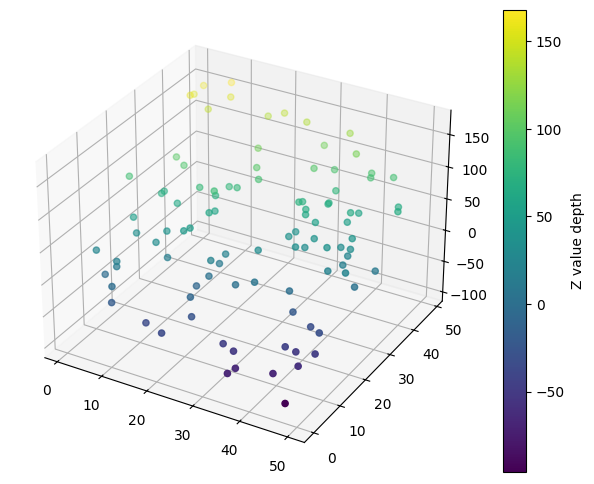

In [ ]:
def f(m, x):
    return m@x

def build_data(m, dim, n, ub):
    xs = (torch.rand(dim, n)*ub).tolist()
    xs.append([1.]*n)
    xs = torch.tensor(xs)
    ys = m@xs + torch.randn(1, n)*ub**0.5
    return xs, ys

xs, ys = build_data(torch.tensor([[-2, 4, -1]]).float(), 2, 100, 50)
print(xs.shape, ys.shape)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc = ax.scatter(xs[0], xs[1], ys, c=ys, cmap = 'viridis')
fig.colorbar(sc, ax=ax, label='Z value depth')

In [ ]:
m = torch.tensor([[5, 5, 5]]).float()
iterations = 8000
lr = 0.001

loss = 0.5 * ((ys - f(m, xs))**2).mean()
loss

tensor(29784.1230)

In [ ]:
print(((ys - f(m, xs))*xs).mean(dim = 1))

tensor([-7504.3774, -5814.0781,  -222.2841])


In [ ]:
for i in range(iterations):
    dm = -((ys - f(m, xs))*xs).mean(dim = 1)
    m += -lr*dm

In [ ]:
loss = 0.5 * ((ys - f(m, xs))**2).mean()
loss

tensor(23.0192)

In [ ]:
m

tensor([[-1.9152,  3.9192, -1.0345]])

/tmp/ipykernel_1068/2143307061.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Z = (m@grid_input).reshape(X0.shape)


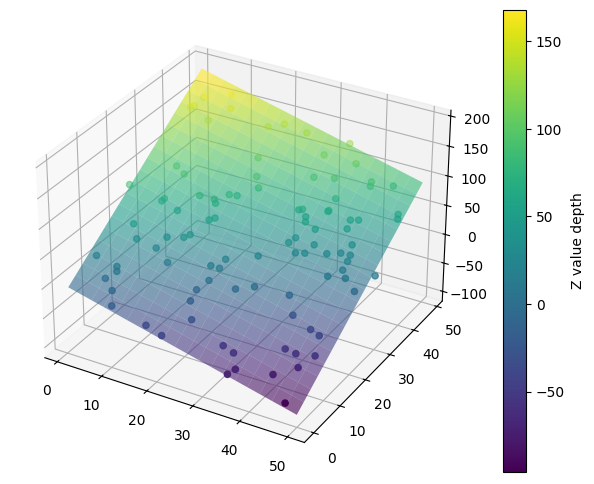

In [ ]:
import numpy as np

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc = ax.scatter(xs[0], xs[1], ys, c=ys, cmap = 'viridis')
fig.colorbar(sc, ax=ax, label='Z value depth')

x0_range = np.linspace(xs[0].min(), xs[0].max(), 20)
x1_range = np.linspace(xs[1].min(), xs[1].max(), 20)
X0, X1 = np.meshgrid(x0_range, x1_range)

grid_input = np.vstack([X0.ravel(), X1.ravel(), np.ones(X0.size)])
Z = (m@grid_input).reshape(X0.shape)
plane = ax.plot_surface(X0, X1, Z, cmap='viridis', alpha=0.6)

plt.show()